# Shor's algorithm on N = 15, and what it would take to break RSA-2048 versus the Agile-HQ-PQC tiers

**What this notebook does**

1. **Part A** builds Shor's order-finding circuit in Qiskit, factors **15 = 3 x 5** on a simulator and plots the measured distribution.
2. **Part B** puts published resource estimates for breaking **RSA-2048** next to the three security tiers (Tier 1 / 3 / 5) of the project.

**What it does not do.** A simulator tracks 2^q amplitudes for q qubits, so it can run Shor on toy numbers only. Part A is an illustration of the *principle* that makes RSA and elliptic-curve key exchange fall to a quantum computer. The real-world scale comes from the literature estimates in Part B, which are copied from the cited papers and are **not** computed here. Shor's algorithm does not apply to the lattice problems behind ML-KEM and ML-DSA, so the tiers are compared on their best-known attack costs instead.

Everything is read-only with respect to the project: it imports the tier table when it can and otherwise falls back to a built-in copy.

In [1]:
import sys, math, json, warnings
from fractions import Fraction
from math import gcd
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=UserWarning)

import qiskit
from qiskit import QuantumCircuit, transpile
try:
    from qiskit_aer import AerSimulator
    BACKEND = "qiskit-aer AerSimulator"
except Exception:                       # Aer missing: fall back to the pure-Qiskit sampler
    AerSimulator = None
    BACKEND = "qiskit.primitives.StatevectorSampler (qiskit-aer not installed)"

print("qiskit", qiskit.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)
print("simulator backend:", BACKEND)

# --- where to save figures (project's reports/ folder when run from <project>/notebooks) ----
HERE = Path.cwd()
ROOT = HERE.parent if (HERE.parent / "agile_hq_pqc").exists() else HERE
OUT = ROOT / "reports"
OUT.mkdir(exist_ok=True)
print("figures and results are saved to:", OUT.relative_to(ROOT) if OUT.is_relative_to(ROOT) else OUT)

# --- the project's tiers (import if available, otherwise a built-in copy of the same table) --
FALLBACK_TIERS = {
    1: dict(kem="ML-KEM-512",  dsa="ML-DSA-44", aead="ChaCha20-Poly1305", kem_ct=768,  dsa_sig=2420),
    3: dict(kem="ML-KEM-768",  dsa="ML-DSA-65", aead="AES-256-GCM",       kem_ct=1088, dsa_sig=3309),
    5: dict(kem="ML-KEM-1024", dsa="ML-DSA-87", aead="AES-256-GCM",       kem_ct=1568, dsa_sig=4627),
}
try:
    sys.path.insert(0, str(ROOT))
    from agile_hq_pqc.core.tiers import TIERS
    TIER_TABLE = {lv: dict(kem=t.kem, dsa=t.dsa, aead=t.aead, kem_ct=t.kem_ct_bytes, dsa_sig=t.dsa_sig_bytes)
                  for lv, t in TIERS.items()}
    TIER_SOURCE = "imported from agile_hq_pqc.core.tiers"
except Exception as e:
    TIER_TABLE, TIER_SOURCE = FALLBACK_TIERS, f"built-in copy (project not importable: {type(e).__name__})"
assert TIER_TABLE == FALLBACK_TIERS, "tier table differs from the one this notebook's numbers were prepared for"
print("tier table:", TIER_SOURCE)
for lv in (1, 3, 5):
    print(f"  Tier {lv}: {TIER_TABLE[lv]['kem']} + {TIER_TABLE[lv]['dsa']} + {TIER_TABLE[lv]['aead']}")

# --- chart style (neutral surface, thin marks, recessive grid; colour = job, not decoration) --
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"      # validated categorical slots 1-3
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False,
})

qiskit 2.5.2 | numpy 2.2.6 | matplotlib 3.10.9
simulator backend: qiskit-aer AerSimulator
figures and results are saved to: reports
tier table: imported from agile_hq_pqc.core.tiers
  Tier 1: ML-KEM-512 + ML-DSA-44 + ChaCha20-Poly1305
  Tier 3: ML-KEM-768 + ML-DSA-65 + AES-256-GCM
  Tier 5: ML-KEM-1024 + ML-DSA-87 + AES-256-GCM


## Part A - Shor's algorithm, factoring 15

**Idea.** Pick `a` coprime to N = 15. The function f(x) = a^x mod 15 repeats with some period `r` (the *order* of a). Finding `r` is the hard part for a classical computer. A quantum computer finds it with **quantum phase estimation** applied to the operation "multiply by a mod 15": measuring the counting register gives a number close to s/r (as a fraction of 2^8), and a continued-fraction step recovers `r`. Then gcd(a^(r/2) +/- 1, 15) yields the factors.

**Circuit.** 8 counting qubits in superposition, 4 work qubits holding y (starting at y = 1), a controlled "multiply by a^(2^j) mod 15" for each counting qubit j, then an inverse quantum Fourier transform and measurement. Total 12 qubits. The multiplication gates are the standard swap-and-flip constructions that exist for the six values a in {2, 4, 7, 8, 11, 13}; the next cell **verifies** each one against ordinary arithmetic before it is used.

In [2]:
N = 15
N_COUNT = 8                      # counting qubits => phase resolution 1/256
VALID_A = [2, 4, 7, 8, 11, 13]   # coprime to 15 and not 1 or 14

def mult_by_a_mod15(a, power=1):
    """4-qubit circuit implementing |y> -> |a^power * y mod 15> for y in 1..14 (swap/X networks)."""
    U = QuantumCircuit(4)
    for _ in range(power):
        if a in (2, 13):
            U.swap(2, 3); U.swap(1, 2); U.swap(0, 1)
        if a in (7, 8):
            U.swap(0, 1); U.swap(1, 2); U.swap(2, 3)
        if a in (4, 11):
            U.swap(1, 3); U.swap(0, 2)
        if a in (7, 11, 13):
            for q in range(4):
                U.x(q)
    return U

# --- self-check: the gate networks really compute a*y mod 15 -------------------------------
from qiskit.quantum_info import Operator
for a in VALID_A:
    for power in (1, 2, 4):
        M = Operator(mult_by_a_mod15(a, power)).data
        for y in range(1, 15):
            assert int(np.argmax(np.abs(M[:, y]))) == (pow(a, power, N) * y) % N, (a, power, y)
print("verified: gate networks implement y -> a^k * y (mod 15) for a in", VALID_A, "and k in {1, 2, 4}")

def controlled_mult(a, power):
    g = mult_by_a_mod15(a, power).to_gate()
    g.name = f"{a}^{power} mod 15"
    return g.control()

def inverse_qft(n):
    qc = QuantumCircuit(n, name="QFT^-1")
    for q in range(n // 2):
        qc.swap(q, n - q - 1)
    for j in range(n):
        for m in range(j):
            qc.cp(-np.pi / 2 ** (j - m), m, j)
        qc.h(j)
    return qc

def shor_circuit(a, n_count=N_COUNT):
    qc = QuantumCircuit(n_count + 4, n_count)
    qc.h(range(n_count))                       # uniform superposition over exponents x
    qc.x(n_count)                              # work register = |y = 1>
    for q in range(n_count):                   # controlled a^(2^q) mod 15
        qc.append(controlled_mult(a, 2 ** q), [q] + [n_count + i for i in range(4)])
    qc.append(inverse_qft(n_count).to_gate(), range(n_count))
    qc.measure(range(n_count), range(n_count))
    return qc

def run(qc, shots=2048, seed=2026):
    if AerSimulator is not None:
        sim = AerSimulator(seed_simulator=seed)
        return sim.run(transpile(qc, sim), shots=shots).result().get_counts()
    from qiskit.primitives import StatevectorSampler
    res = StatevectorSampler(seed=seed).run([qc], shots=shots).result()[0]
    return res.data.c.get_counts()

qc7 = shor_circuit(7)
print(f"circuit for a = 7: {qc7.num_qubits} qubits, {qc7.num_clbits} classical bits")

verified: gate networks implement y -> a^k * y (mod 15) for a in [2, 4, 7, 8, 11, 13] and k in {1, 2, 4}
circuit for a = 7: 12 qubits, 8 classical bits


### Run a = 7 and plot the measured counting register

distinct outcomes: 4 | top outcomes: [(128, 1037), (64, 1037), (192, 1015), (0, 1007)]


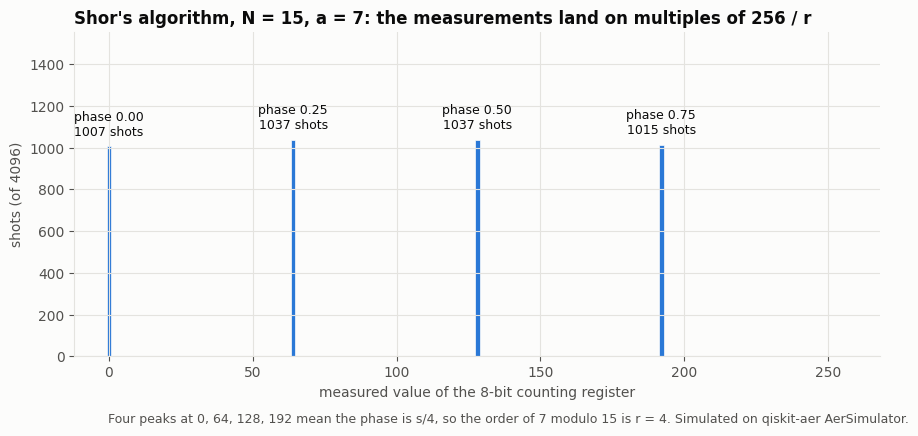

In [3]:
SHOTS = 4096
counts7 = run(qc7, SHOTS)
vals = {int(k, 2): v for k, v in counts7.items()}
print("distinct outcomes:", len(vals), "| top outcomes:", sorted(vals.items(), key=lambda kv: -kv[1])[:6])

xs = np.arange(2 ** N_COUNT)
ys = np.array([vals.get(int(x), 0) for x in xs])

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(xs, ys, width=1.6, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
peaks = sorted(vals, key=lambda k: -vals[k])[:4]
for p in sorted(peaks):
    ax.annotate(f"phase {p / 2 ** N_COUNT:.2f}\n{vals[p]} shots",
                (p, vals[p]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, color=INK)
ax.set_xlim(-12, 2 ** N_COUNT + 12)
ax.set_ylim(0, max(ys) * 1.5)
ax.set_xlabel("measured value of the 8-bit counting register")
ax.set_ylabel(f"shots (of {SHOTS})")
ax.set_title("Shor's algorithm, N = 15, a = 7: the measurements land on multiples of 256 / r")
fig.text(0.125, -0.02, "Four peaks at 0, 64, 128, 192 mean the phase is s/4, so the order of 7 modulo 15 is r = 4. "
         f"Simulated on {BACKEND}.", fontsize=9, color=INK2)
fig.tight_layout()
fig.savefig(OUT / "shor_n15_histogram.png", dpi=160, bbox_inches="tight")
plt.show()

### Classical post-processing: from a measurement to the factors

For each measured value the phase is `value / 256`. The fraction with denominator at most 15 closest to the phase gives a candidate order `r`. A candidate is accepted only if `a^r = 1 (mod 15)`; then the factors are `gcd(a^(r/2) - 1, 15)` and `gcd(a^(r/2) + 1, 15)`.

In [4]:
def factors_from_measurement(a, value, n_count=N_COUNT):
    phase = value / 2 ** n_count
    r = Fraction(phase).limit_denominator(N).denominator
    if r % 2 or pow(a, r, N) != 1 or pow(a, r // 2, N) == N - 1:
        return r, None
    p, q = gcd(pow(a, r // 2) - 1, N), gcd(pow(a, r // 2) + 1, N)
    return (r, (p, q)) if {p, q} == {3, 5} else (r, None)

print("a = 7, every distinct outcome:")
print(f"{'value':>6} {'phase':>8} {'shots':>6}  {'candidate r':>11}  result")
for v in sorted(vals):
    if vals[v] < 20:           # skip the small noise-free tail of the distribution
        continue
    r, f = factors_from_measurement(7, v)
    print(f"{v:>6} {v/256:>8.4f} {vals[v]:>6}  {r:>11}  {'factors ' + str(f) if f else 'retry (r odd, wrong, or trivial)'}")

a = 7, every distinct outcome:
 value    phase  shots  candidate r  result
     0   0.0000   1007            1  retry (r odd, wrong, or trivial)
    64   0.2500   1037            4  factors (3, 5)
   128   0.5000   1037            2  retry (r odd, wrong, or trivial)
   192   0.7500   1015            4  factors (3, 5)


### All six valid bases: how often one run of the quantum circuit yields the factors

In [5]:
rows, results = [], {}
for a in VALID_A:
    c = run(shor_circuit(a), SHOTS, seed=2026 + a)
    ok = tot = 0
    seen_r = {}
    for k, n in c.items():
        r, f = factors_from_measurement(a, int(k, 2))
        tot += n
        if f:
            ok += n
            seen_r[r] = seen_r.get(r, 0) + n
    true_r = next(r for r in range(1, 16) if pow(a, r, N) == 1)
    rows.append((a, true_r, ok / tot))
    results[a] = dict(true_order=true_r, success_rate=ok / tot, shots=tot)

table = ["| a | true order r | single-run success | expected runs to success |", "|---:|---:|---:|---:|"]
for a, r, s in rows:
    table.append(f"| {a} | {r} | {s:.1%} | {1/s:.1f} |")
display(Markdown("\n".join(table)))
print("Each run that fails is simply repeated; with success ~50% per run the expected number of runs is about 2.")
(OUT / "shor_n15_results.json").write_text(json.dumps(
    dict(N=N, shots=SHOTS, backend=BACKEND, qiskit=qiskit.__version__, per_base=results), indent=1))

| a | true order r | single-run success | expected runs to success |
|---:|---:|---:|---:|
| 2 | 4 | 51.4% | 1.9 |
| 4 | 2 | 50.1% | 2.0 |
| 7 | 4 | 50.0% | 2.0 |
| 8 | 4 | 51.2% | 2.0 |
| 11 | 2 | 48.7% | 2.1 |
| 13 | 4 | 49.8% | 2.0 |

Each run that fails is simply repeated; with success ~50% per run the expected number of runs is about 2.


621

In [6]:
# Circuit cost: how big is even this toy instance once compiled to one- and two-qubit gates?
t = transpile(qc7, basis_gates=["u", "cx"], optimization_level=1)
ops = t.count_ops()
print(f"N = 15, a = 7  ->  {t.num_qubits} qubits, depth {t.depth()}, "
      f"{ops.get('cx', 0)} CX gates, {sum(ops.values())} gates in total")
print("This textbook circuit repeats the multiply step 2^j times for counting qubit j, which is wasteful. "
      "It is kept because it is easy to read; real circuits use modular-exponentiation arithmetic instead.")

N = 15, a = 7  ->  12 qubits, depth 24035, 13328 CX gates, 31275 gates in total
This textbook circuit repeats the multiply step 2^j times for counting qubit j, which is wasteful. It is kept because it is easy to read; real circuits use modular-exponentiation arithmetic instead.


## Part B - What breaking RSA-2048 would take, next to the tiers

### Published estimates (copied from the sources, checked 2026-10-13)

All "physical qubit" figures assume a surface-code or similar fault-tolerant machine with a 0.1 % physical error rate, 1 microsecond code cycle and 10 microsecond reaction time, unless the source says otherwise. They are theoretical projections: no such machine exists today. The two 2026 results are preprints.

In [7]:
# Every number below is taken from the cited abstract / table; None = not stated in the source.
RSA_ESTIMATES = [
    dict(year=2019.4, label="Gidney & Ekera 2019", qubits=20_000_000, runtime="about 8 hours",
         toffoli=None, logical=None, src="arXiv:1905.09749 (Quantum 5, 433, 2021)"),
    dict(year=2025.4, label="Gidney 2025", qubits=897_864, runtime="4.96 days (under a week)",
         toffoli=6.5e9, logical=1537, src="arXiv:2505.15917, section 3.2 and Table 5"),
    dict(year=2026.1, label="Webster et al. 2026 (Pinnacle, QLDPC codes)", qubits=100_000,
         runtime="not in the abstract", toffoli=None, logical=None,
         src="arXiv:2602.11457 v2 (preprint); figure is an upper bound: 'fewer than 100 000'"),
]
P256_ESTIMATE = dict(year=2026.25, label="Cain et al. 2026, P-256 (neutral atoms)", qubits=26_000,
                     runtime="a few days (RSA-2048: 1 to 2 orders of magnitude longer)",
                     src="arXiv:2603.28627 (preprint); a different problem: elliptic-curve discrete log")

lines = ["| Estimate | Physical qubits | Runtime | Toffoli gates | Logical qubits | Source |", "|---|---:|---|---:|---:|---|"]
for e in RSA_ESTIMATES:
    lines.append(f"| {e['label']} | {e['qubits']:,} | {e['runtime']} | "
                 f"{'%.1e' % e['toffoli'] if e['toffoli'] else '-'} | {e['logical'] or '-'} | {e['src']} |")
e = P256_ESTIMATE
lines.append(f"| {e['label']} | {e['qubits']:,} | {e['runtime']} | - | - | {e['src']} |")
display(Markdown("\n".join(lines)))

| Estimate | Physical qubits | Runtime | Toffoli gates | Logical qubits | Source |
|---|---:|---|---:|---:|---|
| Gidney & Ekera 2019 | 20,000,000 | about 8 hours | - | - | arXiv:1905.09749 (Quantum 5, 433, 2021) |
| Gidney 2025 | 897,864 | 4.96 days (under a week) | 6.5e+09 | 1537 | arXiv:2505.15917, section 3.2 and Table 5 |
| Webster et al. 2026 (Pinnacle, QLDPC codes) | 100,000 | not in the abstract | - | - | arXiv:2602.11457 v2 (preprint); figure is an upper bound: 'fewer than 100 000' |
| Cain et al. 2026, P-256 (neutral atoms) | 26,000 | a few days (RSA-2048: 1 to 2 orders of magnitude longer) | - | - | arXiv:2603.28627 (preprint); a different problem: elliptic-curve discrete log |

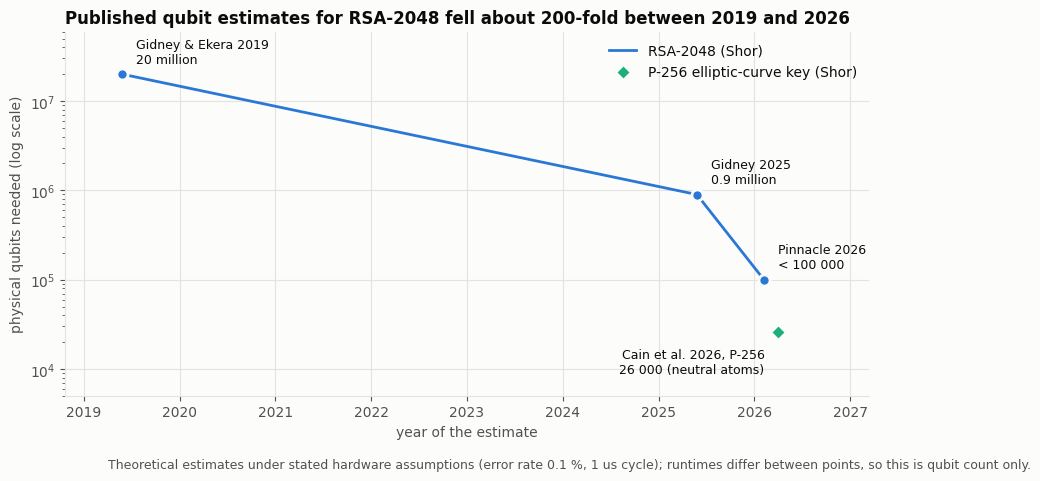

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.6))
xs = [e["year"] for e in RSA_ESTIMATES]; ys = [e["qubits"] for e in RSA_ESTIMATES]
ax.plot(xs, ys, color=BLUE, linewidth=2, zorder=2, label="RSA-2048 (Shor)")
ax.scatter(xs, ys, s=64, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
ax.scatter([P256_ESTIMATE["year"]], [P256_ESTIMATE["qubits"]], s=64, marker="D", color=AQUA,
           edgecolor=SURFACE, linewidth=2, zorder=3, label="P-256 elliptic-curve key (Shor)")
notes = [("Gidney & Ekera 2019\n20 million", (0, 10)), ("Gidney 2025\n0.9 million", (0, 10)),
         ("Pinnacle 2026\n< 100 000", (0, 12))]
for e, (txt, off) in zip(RSA_ESTIMATES, notes):
    ax.annotate(txt, (e["year"], e["qubits"]), textcoords="offset points", xytext=(10, 8),
                fontsize=9, color=INK, ha="left")
ax.annotate("Cain et al. 2026, P-256\n26 000 (neutral atoms)", (P256_ESTIMATE["year"], P256_ESTIMATE["qubits"]),
            textcoords="offset points", xytext=(-10, -30), fontsize=9, color=INK, ha="right")
ax.set_yscale("log"); ax.set_ylim(5_000, 6e7); ax.set_xlim(2018.8, 2027.2)
ax.set_ylabel("physical qubits needed (log scale)"); ax.set_xlabel("year of the estimate")
ax.set_title("Published qubit estimates for RSA-2048 fell about 200-fold between 2019 and 2026")
ax.legend(loc="upper right")
fig.text(0.125, -0.03, "Theoretical estimates under stated hardware assumptions (error rate 0.1 %, 1 us cycle); "
         "runtimes differ between points, so this is qubit count only.", fontsize=9, color=INK2)
fig.tight_layout()
fig.savefig(OUT / "rsa2048_qubit_estimates.png", dpi=160, bbox_inches="tight")
plt.show()

### RSA-2048 versus the tiers: cost of the best known attack

Shor's algorithm breaks RSA in polynomial time, so its cost is small: **about 6.5 x 10^9 logical Toffoli gates (2^32.6)** per factoring on a fault-tolerant machine ([Gidney 2025](https://arxiv.org/abs/2505.15917)). The tiers use lattice-based ML-KEM, for which no polynomial-time quantum algorithm is known. Their security is stated through the **core-SVP** estimate of the best lattice attack (classical and quantum sieving), taken from the CRYSTALS-Kyber round-3 specification (Table 4, p. 21), plus NIST's reference cost for each security category.

| Tier | KEM | NIST category | Core-SVP classical (bits) | Core-SVP quantum (bits) | Refined classical estimate, log2(gates) | NIST category reference, log2(classical gates) |
|---|---|---:|---:|---:|---:|---:|
| 1 | ML-KEM-512 | 1 (AES-128 search) | 118 | 107 | 151.5 | 143 |
| 3 | ML-KEM-768 | 3 (AES-192 search) | 182 | 165 | 215.1 | 207 |
| 5 | ML-KEM-1024 | 5 (AES-256 search) | 256 | 232 | 287.3 | 272 |

**Read the units with care.** The bars below mix three measures: logical Toffoli gates (Shor), core-SVP "bits" (a deliberately conservative lattice-cost estimate that leaves out memory and overheads) and NIST's classical gate counts. They are comparable as **orders of magnitude only**. This is why core-SVP for Tier 1 (2^118) sits left of the category-1 reference (2^143) while the refined gate estimate (2^151.5) sits right of it.

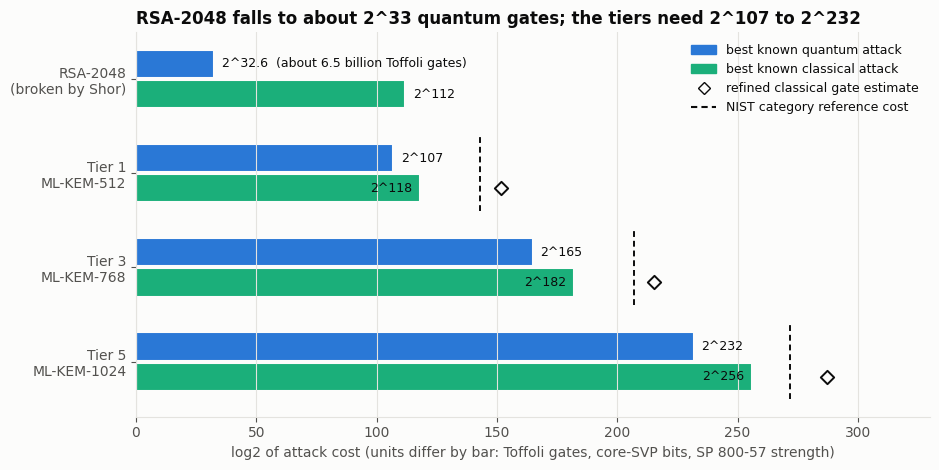

In [9]:
# Source tables (copied; see the Sources cell). Keys are the algorithm names used by the tiers.
KEM_SECURITY = {   # CRYSTALS-Kyber round-3 spec, Table 4 (p. 21)
    "ML-KEM-512":  dict(cat=1, svp_classical=118, svp_quantum=107, refined=151.5, nist_ref=143),
    "ML-KEM-768":  dict(cat=3, svp_classical=182, svp_quantum=165, refined=215.1, nist_ref=207),
    "ML-KEM-1024": dict(cat=5, svp_classical=256, svp_quantum=232, refined=287.3, nist_ref=272),
}
DSA_SECURITY = {   # CRYSTALS-Dilithium round-3 spec, Table 1 (p. 8), LWE core-SVP
    "ML-DSA-44": dict(cat=2, svp_classical=123, svp_quantum=112),
    "ML-DSA-65": dict(cat=3, svp_classical=182, svp_quantum=165),
    "ML-DSA-87": dict(cat=5, svp_classical=252, svp_quantum=229),
}
SHOR_LOG2_TOFFOLI = math.log2(6.5e9)          # Gidney 2025, Table 5
RSA2048_CLASSICAL_BITS = 112                  # NIST SP 800-57 Part 1: RSA-2048 provides 112 bits of strength

rows = [("RSA-2048\n(broken by Shor)", SHOR_LOG2_TOFFOLI, RSA2048_CLASSICAL_BITS, None, None)]
for lv in (1, 3, 5):
    k = TIER_TABLE[lv]["kem"]; s = KEM_SECURITY[k]
    rows.append((f"Tier {lv}\n{k}", s["svp_quantum"], s["svp_classical"], s["refined"], s["nist_ref"]))

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ypos = np.arange(len(rows))[::-1]
h = 0.30
for y, (name, q, c, refined, ref) in zip(ypos, rows):
    ax.barh(y + h / 2 + 0.01, q, height=h, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
    ax.barh(y - h / 2 - 0.01, c, height=h, color=AQUA, edgecolor=SURFACE, linewidth=1.5)
    ax.text(q + 3, y + h / 2 + 0.01, f"2^{q:.0f}" if y != ypos[0] else f"2^{q:.1f}  (about 6.5 billion Toffoli gates)",
            va="center", fontsize=9, color=INK)
    if refined is None:
        ax.text(c + 3, y - h / 2 - 0.01, f"2^{c:.0f}", va="center", fontsize=9, color=INK)
    else:                                   # inside the bar end, clear of the dashed NIST line
        ax.text(c - 3, y - h / 2 - 0.01, f"2^{c:.0f}", va="center", ha="right", fontsize=9, color=INK)
    if refined is not None:
        ax.scatter([refined], [y - h / 2 - 0.01], marker="D", s=46, facecolor=SURFACE, edgecolor=INK, linewidth=1.4, zorder=4)
        ax.plot([ref, ref], [y - 0.4, y + 0.4], color=INK, linewidth=1.4, linestyle=(0, (3, 2)), zorder=3)
ax.set_yticks(ypos); ax.set_yticklabels([r[0] for r in rows])
ax.set_xlim(0, 330); ax.set_xlabel("log2 of attack cost (units differ by bar: Toffoli gates, core-SVP bits, SP 800-57 strength)")
ax.grid(axis="y", visible=False)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="best known quantum attack"),
                   Patch(color=AQUA, label="best known classical attack"),
                   Line2D([], [], marker="D", linestyle="", markerfacecolor=SURFACE, markeredgecolor=INK, label="refined classical gate estimate"),
                   Line2D([], [], color=INK, linestyle=(0, (3, 2)), label="NIST category reference cost")],
          loc="upper right", fontsize=9)
ax.set_title("RSA-2048 falls to about 2^33 quantum gates; the tiers need 2^107 to 2^232")
fig.tight_layout()
fig.savefig(OUT / "rsa2048_vs_tiers.png", dpi=160, bbox_inches="tight")
plt.show()

In [10]:
# The same comparison for the signature half of each tier, plus the cost the tiers pay in bytes.
lines = ["| Tier | Signature | NIST category | Core-SVP classical | Core-SVP quantum | KEM ciphertext (bytes) | Signature (bytes) | AEAD |",
         "|---|---|---:|---:|---:|---:|---:|---|"]
for lv in (1, 3, 5):
    t = TIER_TABLE[lv]; d = DSA_SECURITY[t["dsa"]]
    lines.append(f"| {lv} | {t['dsa']} | {d['cat']} | {d['svp_classical']} | {d['svp_quantum']} | {t['kem_ct']} | {t['dsa_sig']} | {t['aead']} |")
lines.append("| RSA-2048 / X25519 / Ed25519 (for scale) | classical | - | - | broken by Shor | 32 | 64 (Ed25519) | - |")
display(Markdown("\n".join(lines)))

| Tier | Signature | NIST category | Core-SVP classical | Core-SVP quantum | KEM ciphertext (bytes) | Signature (bytes) | AEAD |
|---|---|---:|---:|---:|---:|---:|---|
| 1 | ML-DSA-44 | 2 | 123 | 112 | 768 | 2420 | ChaCha20-Poly1305 |
| 3 | ML-DSA-65 | 3 | 182 | 165 | 1088 | 3309 | AES-256-GCM |
| 5 | ML-DSA-87 | 5 | 252 | 229 | 1568 | 4627 | AES-256-GCM |
| RSA-2048 / X25519 / Ed25519 (for scale) | classical | - | - | broken by Shor | 32 | 64 (Ed25519) | - |

### Why a simulator cannot be pushed to real key sizes

A state-vector simulator stores 2^q complex numbers (16 bytes each) for q qubits. Beauregard's circuit factors an n-bit number with 2n + 3 qubits, so the memory needed explodes with the key size.

state-vector limit 30 qubits (16 GiB) -> numbers up to 13 bits (N < 8,192) with the 2n+3 circuit
RSA-2048 with the 2n+3 circuit: 4099 qubits -> state vector of about 10^1235 bytes (the observable universe holds roughly 10^80 atoms)


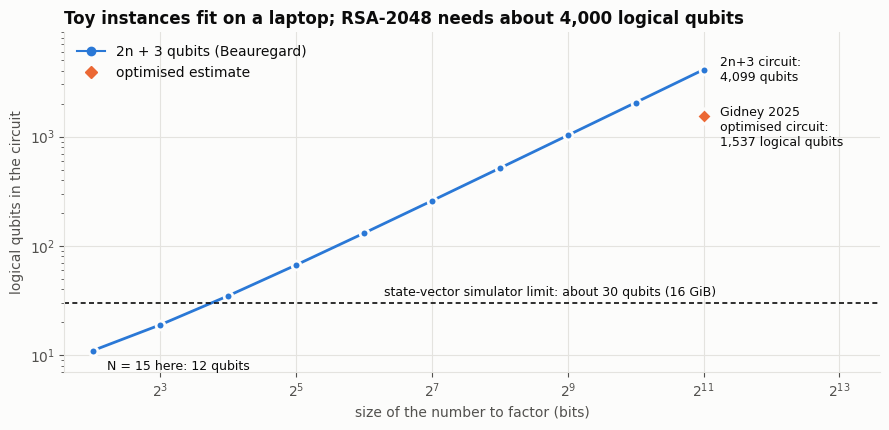

In [11]:
def beauregard_qubits(n_bits): return 2 * n_bits + 3
def statevector_bytes(q): return 16 * 2 ** q

bits = np.array([4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048])
qubits = np.array([beauregard_qubits(int(b)) for b in bits])
LIMIT_Q = 30                                   # 2^30 amplitudes = 16 GiB: a well-equipped workstation
max_bits = (LIMIT_Q - 3) // 2
print(f"state-vector limit {LIMIT_Q} qubits ({statevector_bytes(LIMIT_Q) / 2**30:.0f} GiB) -> numbers up to {max_bits} bits "
      f"(N < {2 ** max_bits:,}) with the 2n+3 circuit")
q2048 = beauregard_qubits(2048)
print(f"RSA-2048 with the 2n+3 circuit: {q2048} qubits -> state vector of about 10^{q2048 * math.log10(2) + math.log10(16):.0f} bytes "
      f"(the observable universe holds roughly 10^80 atoms)")

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(bits, qubits, color=BLUE, linewidth=2, zorder=2)
ax.scatter(bits, qubits, s=40, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
ax.axhline(LIMIT_Q, color=INK, linewidth=1.2, linestyle=(0, (3, 2)))
ax.text(2 ** 6.3, LIMIT_Q * 1.15, "state-vector simulator limit: about 30 qubits (16 GiB)", fontsize=9, color=INK)
ax.scatter([2048], [1537], marker="D", s=64, color=ORANGE, edgecolor=SURFACE, linewidth=2, zorder=3)
ax.annotate("Gidney 2025\noptimised circuit:\n1,537 logical qubits", (2048, 1537), textcoords="offset points",
            xytext=(12, -8), ha="left", va="center", fontsize=9, color=INK)
ax.annotate("2n+3 circuit:\n4,099 qubits", (2048, q2048), textcoords="offset points", xytext=(12, 0), ha="left", va="center", fontsize=9, color=INK)
ax.annotate("N = 15 here: 12 qubits", (4, 11), textcoords="offset points", xytext=(10, -14), fontsize=9, color=INK)
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlim(3, 2 ** 13.6); ax.set_ylim(7, 9000)
ax.set_xlabel("size of the number to factor (bits)"); ax.set_ylabel("logical qubits in the circuit")
ax.set_title("Toy instances fit on a laptop; RSA-2048 needs about 4,000 logical qubits")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], color=BLUE, marker="o", label="2n + 3 qubits (Beauregard)"),
                   Line2D([], [], color=ORANGE, marker="D", linestyle="", label="optimised estimate")], loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "shor_simulation_scaling.png", dpi=160, bbox_inches="tight")
plt.show()

## What to take from this

- **Part A** shows the mechanism: Shor's algorithm turns factoring into period finding, and the quantum Fourier transform finds the period. It works on 15; scaling it to 2048 bits needs thousands of error-corrected logical qubits.
- **Part B** shows the trend that motivates the project: the published qubit estimate for RSA-2048 fell from 20 million (2019) to under a million (2025) and, in a 2026 preprint, to under 100,000. Recorded traffic encrypted with RSA or X25519 becomes readable when such a machine exists (*harvest now, decrypt later*).
- **The tiers** sit at 2^107 to 2^232 in the best-known quantum attack cost. Higher tiers cost more bytes (ciphertext 768 -> 1,568 bytes, signature 2,420 -> 4,627 bytes) and more time; that is the trade-off the controller manages. No tier is weakened by Shor, so the controller never has to trade away quantum safety, only margin: even Tier 1 is NIST Category 1 for key establishment (ML-DSA-44 signatures are Category 2).
- **Honest limits.** Core-SVP is a conservative estimate, not a proof; the 2026 estimates are preprints; and the simulator demonstrates principle, not scale. The project's hybrid design (X25519 + ML-KEM, Ed25519 + ML-DSA) stays secure if either half holds.

### Sources

- Gidney, *How to factor 2048 bit RSA integers with less than a million noisy qubits*, arXiv:2505.15917 (May 2025): [arxiv.org/abs/2505.15917](https://arxiv.org/abs/2505.15917). 897,864 physical qubits, 4.96 days, 6.5 billion Toffoli gates, 1,537 logical qubits (section 3.2, Table 5).
- Gidney and Ekera, *How to factor 2048 bit RSA integers in 8 hours using 20 million noisy qubits*, Quantum 5, 433 (2021), arXiv:1905.09749.
- Webster et al., *The Pinnacle Architecture: Reducing the cost of breaking RSA-2048 to 100 000 physical qubits using quantum LDPC codes*, arXiv:2602.11457 (Feb 2026, v2 May 2026; preprint): [arxiv.org/abs/2602.11457](https://arxiv.org/abs/2602.11457).
- Cain et al., *Shor's algorithm is possible with as few as 10,000 reconfigurable atomic qubits*, arXiv:2603.28627 (Mar 2026; preprint): [arxiv.org/abs/2603.28627](https://arxiv.org/abs/2603.28627).
- CRYSTALS-Kyber specification, round 3 (Jan 2021), Table 4, p. 21: [pq-crystals.org/kyber](https://www.pq-crystals.org/kyber/data/kyber-specification-round3-20210131.pdf). These are the Kyber submission's estimates; FIPS 203 (ML-KEM) is the standardised successor and keeps the same parameter-set sizes.
- CRYSTALS-Dilithium specification, round 3 (Feb 2021), Table 1, p. 8: [pq-crystals.org/dilithium](https://pq-crystals.org/dilithium/data/dilithium-specification-round3-20210208.pdf).
- NIST, *Post-Quantum Cryptography: Security (Evaluation Criteria)* - category reference costs 2^143 / 2^207 / 2^272 classical gates: [csrc.nist.gov](https://csrc.nist.gov/projects/post-quantum-cryptography/post-quantum-cryptography-standardization/evaluation-criteria/security-(evaluation-criteria)).
- NIST SP 800-57 Part 1 Rev. 5: RSA-2048 provides 112 bits of classical security strength.
- Beauregard, *Circuit for Shor's algorithm using 2n+3 qubits*, arXiv:quant-ph/0205095 (2003).
- The swap-and-flip multiplication networks for N = 15 follow the Qiskit textbook's Shor's algorithm chapter.